# Lab 7 tasks

Name: Khair ul wara Hussain

Student Id: FA23-BAI-022

Course: NLP

---
# Lab 07: POS Tagging & Named Entity Recognition

## Setup: imports and model

In [1]:
import json
from collections import Counter
import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from IPython.display import HTML

In [2]:
# downloads the model only if it is not installed already
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

print(nlp.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Task 01: Coarse vs Fine-Grained POS Tags

In [3]:
text1 = "The quick brown fox jumped over the lazy dogs near the river."
doc = nlp(text1)

# (a) tokens with coarse pos_
for token in doc:
    print(f"{token.text:10} {token.pos_}")

The        DET
quick      ADJ
brown      ADJ
fox        NOUN
jumped     VERB
over       ADP
the        DET
lazy       ADJ
dogs       NOUN
near       ADP
the        DET
river      NOUN
.          PUNCT


In [4]:
# (b) pos_ and tag_ in two columns
print(f"{'Token':10} {'pos_':8} {'tag_'}")
for token in doc:
    print(f"{token.text:10} {token.pos_:8} {token.tag_}")

Token      pos_     tag_
The        DET      DT
quick      ADJ      JJ
brown      ADJ      JJ
fox        NOUN     NN
jumped     VERB     VBD
over       ADP      IN
the        DET      DT
lazy       ADJ      JJ
dogs       NOUN     NNS
near       ADP      IN
the        DET      DT
river      NOUN     NN
.          PUNCT    .


In [5]:
# (c) explanation of every unique pos_ and tag_
print("--- pos_ ---")
for pos in sorted(set(token.pos_ for token in doc)):
    print(f"{pos:6} -> {spacy.explain(pos)}")

print("\n--- tag_ ---")
for tag in sorted(set(token.tag_ for token in doc)):
    print(f"{tag:6} -> {spacy.explain(tag)}")

--- pos_ ---
ADJ    -> adjective
ADP    -> adposition
DET    -> determiner
NOUN   -> noun
PUNCT  -> punctuation
VERB   -> verb

--- tag_ ---
.      -> punctuation mark, sentence closer
DT     -> determiner
IN     -> conjunction, subordinating or preposition
JJ     -> adjective (English), other noun-modifier (Chinese)
NN     -> noun, singular or mass
NNS    -> noun, plural
VBD    -> verb, past tense


In [6]:
# (d) distinct tag_ values for each pos_
pos_tags = {}
for token in doc:
    pos_tags.setdefault(token.pos_, set()).add(token.tag_)

for pos, tags in pos_tags.items():
    print(f"{pos:6} {len(tags)} distinct tag(s): {sorted(tags)}")

print("\nTokens whose pos_ has more than one tag_:")
for token in doc:
    if len(pos_tags[token.pos_]) > 1:
        print(f"{token.text:8} pos_={token.pos_}  tag_={token.tag_} ({spacy.explain(token.tag_)})")

DET    1 distinct tag(s): ['DT']
ADJ    1 distinct tag(s): ['JJ']
NOUN   2 distinct tag(s): ['NN', 'NNS']
VERB   1 distinct tag(s): ['VBD']
ADP    1 distinct tag(s): ['IN']
PUNCT  1 distinct tag(s): ['.']

Tokens whose pos_ has more than one tag_:
fox      pos_=NOUN  tag_=NN (noun, singular or mass)
dogs     pos_=NOUN  tag_=NNS (noun, plural)
river    pos_=NOUN  tag_=NN (noun, singular or mass)


## Task 02: Tag Frequency Analysis

In [7]:
text2 = "Ali bought three fresh apples. He carefully washed them and quickly shared them with his friends. Everyone happily enjoyed the sweet fruit."
doc = nlp(text2)

# (a) pos_ counts
pos_counts = {}
for token in doc:
    pos_counts[token.pos_] = pos_counts.get(token.pos_, 0) + 1
print(pos_counts)

{'PROPN': 1, 'VERB': 4, 'NUM': 1, 'ADJ': 2, 'NOUN': 3, 'PUNCT': 3, 'PRON': 5, 'ADV': 3, 'CCONJ': 1, 'ADP': 1, 'DET': 1}


In [8]:
# (b) tag_ counts
tag_counts = {}
for token in doc:
    tag_counts[token.tag_] = tag_counts.get(token.tag_, 0) + 1
print(tag_counts)

{'NNP': 1, 'VBD': 4, 'CD': 1, 'JJ': 2, 'NNS': 2, '.': 3, 'PRP': 3, 'RB': 3, 'CC': 1, 'IN': 1, 'PRP$': 1, 'NN': 2, 'DT': 1}


In [9]:
# (c) sorted from most frequent to least frequent
pos_sorted = dict(sorted(pos_counts.items(), key=lambda x: x[1], reverse=True))
tag_sorted = dict(sorted(tag_counts.items(), key=lambda x: x[1], reverse=True))

print("pos_ frequencies:")
for k, v in pos_sorted.items():
    print(f"{k:6} {v}")

print("\ntag_ frequencies:")
for k, v in tag_sorted.items():
    print(f"{k:6} {v}")

pos_ frequencies:
PRON   5
VERB   4
NOUN   3
PUNCT  3
ADV    3
ADJ    2
PROPN  1
NUM    1
CCONJ  1
ADP    1
DET    1

tag_ frequencies:
VBD    4
.      3
PRP    3
RB     3
JJ     2
NNS    2
NN     2
NNP    1
CD     1
CC     1
IN     1
PRP$   1
DT     1


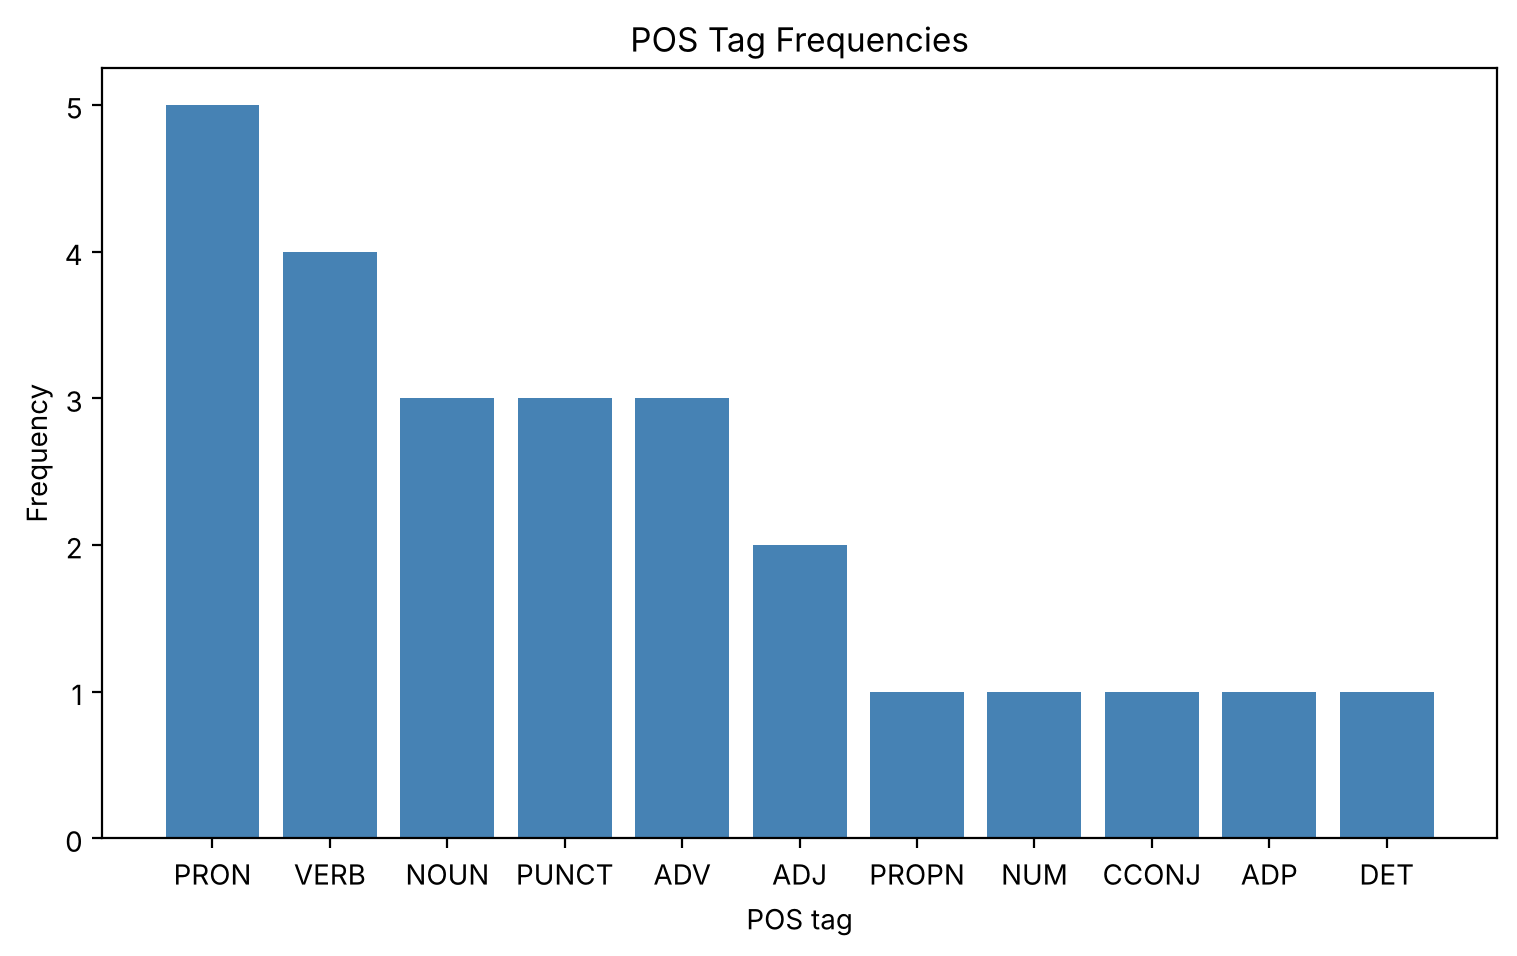

In [10]:
# (d) bar chart of pos_ frequencies
plt.figure(figsize=(9, 5))
plt.bar(pos_sorted.keys(), pos_sorted.values(), color="steelblue")
plt.xlabel("POS tag")
plt.ylabel("Frequency")
plt.title("POS Tag Frequencies")
plt.show()

## Task 03: Context-Dependent Tagging

In [11]:
sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play.",
]

# (a) the word "book"
for i, sent in enumerate(sentences, start=1):
    for token in nlp(sent):
        if token.text.lower() == "book":
            print(f"Sentence {i}: {token.text}  pos_={token.pos_}  tag_={token.tag_}")

Sentence 1: book  pos_=VERB  tag_=VB
Sentence 2: book  pos_=NOUN  tag_=NN


In [12]:
# (b) the word "run"
for i, sent in enumerate(sentences, start=1):
    for token in nlp(sent):
        if token.text.lower() == "run":
            print(f"Sentence {i}: {token.text}  pos_={token.pos_}  tag_={token.tag_}")

Sentence 3: run  pos_=VERB  tag_=VBP
Sentence 4: run  pos_=NOUN  tag_=NN


In [13]:
# (c) compare_word function
def compare_word(word, sentences):
    result = []
    for i, sent in enumerate(sentences):
        for token in nlp(sent):
            if token.text.lower() == word.lower():
                result.append((i, token.pos_, token.tag_))
    return result

print(compare_word("book", sentences))
print(compare_word("run", sentences))

[(0, 'VERB', 'VB'), (1, 'NOUN', 'NN')]
[(2, 'VERB', 'VBP'), (3, 'NOUN', 'NN')]


In [14]:
# (d) two more ambiguous words
light_sents = ["Please turn on the light.", "This bag is very light."]
play_sents = ["The children play in the garden.", "We watched a play at the theatre."]

print("light:", compare_word("light", light_sents))
print("play:", compare_word("play", play_sents))

light: [(0, 'NOUN', 'NN'), (1, 'ADJ', 'JJ')]
play: [(0, 'VERB', 'VBP'), (1, 'NOUN', 'NN')]


## Task 04: Filtering Noise Tokens

In [15]:
messy = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "
doc = nlp(messy)

# (a) all tokens with pos_ (repr shows the space tokens)
for token in doc:
    print(f"{repr(token.text):12} {token.pos_}")

' '          SPACE
'Hello'      INTJ
'!'          PUNCT
'!'          PUNCT
'!'          PUNCT
'The'        DET
'price'      NOUN
'is'         AUX
'$'          SYM
'45.50'      NUM
'...'        PUNCT
'('          PUNCT
'really'     ADV
'?'          PUNCT
')'          PUNCT
'\n\n '      SPACE
'Is'         AUX
'it'         PRON
'worth'      ADJ
'it'         PRON
'?'          PUNCT
'xyz123'     PROPN
'@@'         PROPN


In [16]:
# (b) remove SPACE, PUNCT and X
cleaned = [token.text for token in doc if token.pos_ not in ("SPACE", "PUNCT", "X")]
print(cleaned)

['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']


In [17]:
# (c) how many tokens were removed
total = len(doc)
removed = total - len(cleaned)
print("Total tokens:", total)
print("Removed tokens:", removed)
print(f"Percentage removed: {removed / total * 100:.2f}%")

Total tokens: 23
Removed tokens: 10
Percentage removed: 43.48%


In [18]:
# (d) reusable function
def clean_pos(text, remove=("SPACE", "PUNCT", "X")):
    doc = nlp(text)
    return [(token.text, token.pos_) for token in doc if token.pos_ not in remove]

second_text = "  Wow!!!  The new phone costs $300 ... (really?) ## abc999 ~~ ??? "
print("Before:", [t.text for t in nlp(second_text)])
print("After :", clean_pos(second_text))

Before: ['  ', 'Wow', '!', '!', '!', ' ', 'The', 'new', 'phone', 'costs', '$', '300', '...', '(', 'really', '?', ')', '#', '#', 'abc999', '~~', '?', '?', '?']
After : [('Wow', 'INTJ'), ('The', 'DET'), ('new', 'ADJ'), ('phone', 'NOUN'), ('costs', 'NOUN'), ('$', 'SYM'), ('300', 'NUM'), ('really', 'ADV'), ('#', 'SYM'), ('#', 'NOUN'), ('abc999', 'PROPN'), ('~~', 'NUM')]


## Task 05: Extracting Specific Parts of Speech

In [19]:
text5 = "Fatima quickly opened the old wooden door and slowly walked into the dark room. She carefully placed a small lamp on the heavy table."
doc = nlp(text5)

# (a) nouns
nouns = [token.text for token in doc if token.pos_ in ("NOUN", "PROPN")]
print("Nouns:", nouns)

Nouns: ['Fatima', 'door', 'room', 'lamp', 'table']


In [20]:
# (b) verbs with lemmas
for token in doc:
    if token.pos_ == "VERB":
        print(f"{token.text:8} -> {token.lemma_}")

opened   -> open
walked   -> walk
placed   -> place


In [21]:
# (c) adjective-noun pairs
pairs = []
for i in range(len(doc) - 1):
    if doc[i].pos_ == "ADJ" and doc[i + 1].pos_ in ("NOUN", "PROPN"):
        pairs.append(doc[i].text + " " + doc[i + 1].text)
print(pairs)

['wooden door', 'dark room', 'small lamp', 'heavy table']


In [22]:
# (d) summary table
n_nouns = len([t for t in doc if t.pos_ in ("NOUN", "PROPN")])
n_verbs = len([t for t in doc if t.pos_ == "VERB"])
n_adj = len([t for t in doc if t.pos_ == "ADJ"])
n_adv = len([t for t in doc if t.pos_ == "ADV"])

print(f"{'Part of speech':15} {'Count':5}")
print("-" * 21)
print(f"{'Nouns':15} {n_nouns:5}")
print(f"{'Verbs':15} {n_verbs:5}")
print(f"{'Adjectives':15} {n_adj:5}")
print(f"{'Adverbs':15} {n_adv:5}")

Part of speech  Count
---------------------
Nouns               5
Verbs               3
Adjectives          5
Adverbs             3


## Task 06: Basic Named Entity Recognition

In [23]:
text6 = "Imran Khan visited Google headquarters in California on March 3, 2019, and discussed a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore."
doc = nlp(text6)

# (a) entities with positions
for ent in doc.ents:
    print(f"{ent.text:20} {ent.label_:10} {ent.start_char:4} {ent.end_char:4}")

Khan                 PERSON        6   10
Google               ORG          19   25
California           GPE          42   52
March 3, 2019        DATE         56   69
$2 million           MONEY        87   97
Pakistan             GPE         113  121
Microsoft            ORG         130  139
Amazon               ORG         144  150
Lahore               GPE         176  182


In [24]:
# (b) meaning of every unique label
for label in sorted(set(ent.label_ for ent in doc.ents)):
    print(f"{label:10} -> {spacy.explain(label)}")

DATE       -> Absolute or relative dates or periods
GPE        -> Countries, cities, states
MONEY      -> Monetary values, including unit
ORG        -> Companies, agencies, institutions, etc.
PERSON     -> People, including fictional


In [25]:
# (c) group entities by label
grouped = {}
for ent in doc.ents:
    grouped.setdefault(ent.label_, []).append(ent.text)
print(grouped)

{'PERSON': ['Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}


In [26]:
# (d) count per label
label_counts = Counter(ent.label_ for ent in doc.ents)
for label, count in label_counts.items():
    print(f"{label:10} {count}")

top_label, top_count = label_counts.most_common(1)[0]
print(f"\nLabel with the highest count: {top_label} ({top_count})")

PERSON     1
ORG        3
GPE        3
DATE       1
MONEY      1

Label with the highest count: ORG (3)


## Task 07: Visualizing Entities with displaCy

In [27]:
text7 = "Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to invest 500 million dollars across Asia by 2025."
doc = nlp(text7)

# (a) entity visualization saved as entities.html
html = displacy.render(doc, style="ent", jupyter=False, page=True)
with open("entities.html", "w", encoding="utf-8") as f:
    f.write(html)
displacy.render(doc, style="ent")

In [28]:
# (b) only ORG and GPE
options = {"ents": ["ORG", "GPE"]}
displacy.render(doc, style="ent", options=options)

In [29]:
# (c) custom colors
options = {"ents": ["ORG", "GPE"], "colors": {"ORG": "orange", "GPE": "lightgreen"}}
displacy.render(doc, style="ent", options=options)

In [30]:
# (d) dependency tree of the first sentence saved as dependency.html
first_sent = list(doc.sents)[0].as_doc()
html = displacy.render(first_sent, style="dep", jupyter=False, page=True)
with open("dependency.html", "w", encoding="utf-8") as f:
    f.write(html)
displacy.render(first_sent, style="dep")

## Task 08: Extending the Model with EntityRuler

In [31]:
text8 = "Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework TensorFlow. Her colleague Abbas prefers PyTorch and Pandas."

# (a) plain pretrained model
doc = nlp(text8)
for ent in doc.ents:
    print(f"{ent.text:20} {ent.label_}")

tech_terms = ["NumPy", "TensorFlow", "PyTorch", "Pandas"]
found = [ent.text for ent in doc.ents]
print("\nTech terms not detected at all:", [t for t in tech_terms if t not in found])
print("Tech terms detected with a label:", {ent.text: ent.label_ for ent in doc.ents if ent.text in tech_terms})

Zainab               PERSON
LabTech Solutions    ORG
Abbas                PERSON
PyTorch              PERSON
Pandas               PERSON

Tech terms not detected at all: ['NumPy', 'TensorFlow']
Tech terms detected with a label: {'PyTorch': 'PERSON', 'Pandas': 'PERSON'}


In [32]:
# (b) EntityRuler with the TECH label (placed before ner)
patterns = [
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"},
]

nlp_ruler = spacy.load("en_core_web_sm")
ruler = nlp_ruler.add_pipe("entity_ruler", before="ner")
ruler.add_patterns(patterns)
print(nlp_ruler.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']


In [33]:
# (c) reprocess the text
doc = nlp_ruler(text8)
for ent in doc.ents:
    print(f"{ent.text:20} {ent.label_}")

print("\nAll four are TECH:", all(ent.label_ == "TECH" for ent in doc.ents if ent.text in tech_terms))

Zainab               PERSON
LabTech Solutions    ORG
NumPy                TECH
TensorFlow           TECH
Abbas                PERSON
PyTorch              TECH
Pandas               TECH

All four are TECH: True


In [34]:
# (d) overwrite_ents and ruler position
def run_ruler(position, overwrite):
    model = spacy.load("en_core_web_sm")
    if position == "before":
        r = model.add_pipe("entity_ruler", before="ner", config={"overwrite_ents": overwrite})
    else:
        r = model.add_pipe("entity_ruler", after="ner", config={"overwrite_ents": overwrite})
    r.add_patterns(patterns)
    return model(text8)

for position in ["before", "after"]:
    for overwrite in [False, True]:
        d = run_ruler(position, overwrite)
        print(f"ruler {position} ner, overwrite_ents={overwrite}")
        print([(ent.text, ent.label_) for ent in d.ents])
        print()

ruler before ner, overwrite_ents=False
[('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]



ruler before ner, overwrite_ents=True
[('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]



ruler after ner, overwrite_ents=False
[('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'PERSON'), ('Pandas', 'PERSON')]



ruler after ner, overwrite_ents=True
[('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]



## Task 09: Complete Pipeline: From Raw Text to Structured Information

In [35]:
text9 = "Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%."

# (a) cleaned tokens with pos_ and tag_
def get_tokens(text):
    doc = nlp(text)
    return [(t.text, t.pos_, t.tag_) for t in doc if t.pos_ not in ("SPACE", "PUNCT", "X")]

tokens = get_tokens(text9)
for tok in tokens:
    print(tok)

('Elon', 'PROPN', 'NNP')
('Musk', 'PROPN', 'NNP')
('the', 'DET', 'DT')
('CEO', 'NOUN', 'NN')
('of', 'ADP', 'IN')
('Tesla', 'PROPN', 'NNP')
('announced', 'VERB', 'VBN')
('on', 'ADP', 'IN')
('Tuesday', 'PROPN', 'NNP')
('that', 'SCONJ', 'IN')
('SpaceX', 'PROPN', 'NNP')
('will', 'AUX', 'MD')
('launch', 'VERB', 'VB')
('a', 'DET', 'DT')
('Falcon', 'PROPN', 'NNP')
('rocket', 'NOUN', 'NN')
('from', 'ADP', 'IN')
('Texas', 'PROPN', 'NNP')
('next', 'ADJ', 'JJ')
('month', 'NOUN', 'NN')
('Investors', 'NOUN', 'NNS')
('in', 'ADP', 'IN')
('London', 'PROPN', 'NNP')
('and', 'CCONJ', 'CC')
('Tokyo', 'PROPN', 'NNP')
('reacted', 'VERB', 'VBD')
('quickly', 'ADV', 'RB')
('and', 'CCONJ', 'CC')
('Tesla', 'PROPN', 'NNP')
('shares', 'NOUN', 'NNS')
('rose', 'VERB', 'VBD')
('by', 'ADP', 'IN')
('4', 'NUM', 'CD')
('%', 'NOUN', 'NN')


In [36]:
# (b) EntityRuler with PRODUCT label
print("Model entities only:")
print([(ent.text, ent.label_) for ent in nlp(text9).ents])

nlp_final = spacy.load("en_core_web_sm")
ruler = nlp_final.add_pipe("entity_ruler", before="ner")
ruler.add_patterns([
    {"label": "PRODUCT", "pattern": "Falcon"},
    {"label": "PRODUCT", "pattern": "Tesla shares"},
])

doc = nlp_final(text9)
print("\nFinal entities (model + ruler):")
for ent in doc.ents:
    print(f"{ent.text:15} {ent.label_}")

Model entities only:
[('Elon Musk', 'PERSON'), ('Tesla', 'ORG'), ('Tuesday', 'DATE'), ('SpaceX', 'PERSON'), ('Falcon', 'ORG'), ('Texas', 'GPE'), ('next month', 'DATE'), ('London', 'GPE'), ('Tokyo', 'GPE'), ('Tesla', 'ORG'), ('4%', 'PERCENT')]



Final entities (model + ruler):
Elon Musk       PERSON
Tesla           ORG
Tuesday         DATE
SpaceX          PERSON
Falcon          PRODUCT
Texas           GPE
next month      DATE
London          GPE
Tokyo           GPE
Tesla shares    PRODUCT
4%              PERCENT


In [37]:
# (c) structured output saved to output.json
pos_counts = Counter(pos for _, pos, _ in tokens)

output = {
    "tokens": [{"text": t, "pos": p, "tag": g} for t, p, g in tokens],
    "entities": [{"text": ent.text, "label": ent.label_} for ent in doc.ents],
    "pos_counts": dict(pos_counts),
}

with open("output.json", "w") as f:
    json.dump(output, f, indent=4)

print(json.dumps(output["pos_counts"], indent=2))
print(output["entities"])

{
  "PROPN": 10,
  "DET": 2,
  "NOUN": 6,
  "ADP": 5,
  "VERB": 4,
  "SCONJ": 1,
  "AUX": 1,
  "ADJ": 1,
  "CCONJ": 2,
  "ADV": 1,
  "NUM": 1
}
[{'text': 'Elon Musk', 'label': 'PERSON'}, {'text': 'Tesla', 'label': 'ORG'}, {'text': 'Tuesday', 'label': 'DATE'}, {'text': 'SpaceX', 'label': 'PERSON'}, {'text': 'Falcon', 'label': 'PRODUCT'}, {'text': 'Texas', 'label': 'GPE'}, {'text': 'next month', 'label': 'DATE'}, {'text': 'London', 'label': 'GPE'}, {'text': 'Tokyo', 'label': 'GPE'}, {'text': 'Tesla shares', 'label': 'PRODUCT'}, {'text': '4%', 'label': 'PERCENT'}]


In [38]:
# (d) displaCy with custom colors
colors = {"PERSON": "lightpink", "ORG": "orange", "GPE": "lightgreen", "PRODUCT": "lightblue"}
options = {"ents": ["PERSON", "ORG", "GPE", "PRODUCT"], "colors": colors}
displacy.render(doc, style="ent", options=options)

In [39]:
# each entity with its sentence
for ent in doc.ents:
    print(f"{ent.text} ({ent.label_}) -> {ent.sent.text}")

Elon Musk (PERSON) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Tesla (ORG) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Tuesday (DATE) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
SpaceX (PERSON) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Falcon (PRODUCT) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Texas (GPE) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
next month (DATE) -> Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
London (GPE) -> Investors in London and Tokyo reacted quickly, and Tesla shares